# 헬스 운동 자세 오류의 조건별 판별 가능성 분석
### 3D 키포인트 기반 딥러닝과 수행자 분리 평가

- 데이터: AI Hub 「피트니스 자세 이미지」(dataSetSn=231) **라벨 JSON**(기구 · 바벨/덤벨 · 맨몸, 41종 운동)
- 과제: 운동별 자세 조건(척추 중립, 손목 중립 등 3~5개)의 **정/오류 다중 라벨 분류**
- 평가: **수행자(img_key의 Z코드) 분리** GroupKFold(8) — 같은 사람의 클립은 학습/평가에 동시에 들어가지 않음
- 발표·시연 앱: `app.py` (Streamlit), 보고서: `REPORT.md`

| 연구 질문 | 내용 |
|---|---|
| RQ1 | 3D 키포인트만으로 조건별 정/오류를 얼마나 판별할 수 있는가 |
| RQ2 | 시퀀스 딥러닝(1D-CNN, GRU)이 요약 특징 + 선형 모델보다 어려운 조건에서 나은가 |
| RQ3 | 3D 좌표 vs 2D 5시점 입력 |
| RQ4 | 어려운 조건은 왜 어려운가 |

> 이 노트북은 오래 걸리는 단계(전체 실험 ≈ 1.5시간)를 `.py` 스크립트로 실행한 결과를 불러오고, 핵심 단계(전처리·기준 모델·딥러닝 1개 운동)는 노트북 안에서 직접 실행합니다.

In [1]:
import os, sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
plt.rcParams.update({"font.family": "Malgun Gothic", "axes.unicode_minus": False})
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 40)
sys.path.insert(0, os.getcwd())
from build_cache import JOINTS
from exp_seq import load_cache, norm3d, norm2d, angles3d, summary, fit_predict, metrics, make_keras, REP6
print("작업 폴더:", os.getcwd())

작업 폴더: D:\YOOJIHUN\DL_Project


## 1. 데이터 준비와 검증

tar → 내부 zip → `D{day}-{slot}-{code}.json`(2D 5시점 + 라벨) / `...-3d.json`(3D 좌표). 풀기와 집계는 스크립트로 실행했습니다.

```
python prepare_data.py data dataset/기구.tar "dataset/바벨,덤벨.tar" dataset/맨몸운동.tar ...
python count_data.py data --out logs/counts.json
```

> 2~4절은 원본 데이터 캐시(`cache/`)가 있어야 실행됩니다. 저장소에는 AI Hub 원본 데이터가 없으므로 저장된 출력으로 확인하세요.

**정제 규칙**: ① 16프레임 아닌 클립 제외 ② 라벨·Z코드 없음 제외 ③ 3D 짝 없음 제외(3D 실험) ④ **3D 이상값**(|좌표|>10⁴ 또는 정규화 특징 |f|>50) 제외

In [2]:
cnt = json.load(open("app_data/counts.json", encoding="utf-8"))   # = logs/counts.json (count_data.py 출력)
pd.DataFrame({k: {"2D JSON": v["json_2d"], "3D JSON": v["json_3d"], "2D만": v["only_2d"], "3D만(라벨 없음)": v["only_3d"],
                  "16프레임 아님": v["excluded"].get("2D 프레임 16 아님", 0), "3D 이상값": v["excluded"].get("3D 이상값", 0),
                  "사용 가능 클립": v["usable"], "수행자(Z)": v["performers"], "운동": v["exercises"]} for k, v in cnt.items()}).T

,2D JSON,3D JSON,2D만,3D만(라벨 없음),16프레임 아님,3D 이상값,사용 가능 클립,수행자(Z),운동
기구,4262,4262,0,0,9,0,4253,32,8
맨몸운동,15461,16423,1119,2081,186,1080,13076,62,21
"바벨,덤벨",14745,14745,0,0,92,0,14653,95,14


핸드오프 문서의 기대값(기구 4,262/4,253/32, 바벨·덤벨 14,745/14,653/95, 맨몸 15,461/13,076/62)과 **정확히 일치**합니다.

기존 기준 모델(`analyze_fitness.py`)도 재현했습니다 — 176개 운동×조건 모두 ±0.02 이내(최대 차이 0.0018).

In [3]:
cmp = pd.read_csv("results/baseline_repro_compare.csv")
print(f"재현 조건 수 {len(cmp)} | 클립 수 일치 {(cmp.clips == cmp.clips_repro).mean():.0%} | |정확도 차이| 최대 {cmp['diff'].abs().max():.4f}")

재현 조건 수 176 | 클립 수 일치 100% | |정확도 차이| 최대 0.0018


## 2. 캐시와 전처리

모든 실험은 `build_cache.py`가 만든 캐시(클립별 3D `(16,24,3)`, 2D `(16,5,24,2)`, 라벨, Z코드)를 읽습니다.

- **3D**: Neck 원점 이동 → 클립 평균 어깨너비로 나눔 → `(16, 72)`
- **2D 5시점**: 시점마다 Neck 원점 이동 → 몸통 길이(Neck–Waist)로 나눔 → `(16, 240)` (측면 시점은 어깨너비가 0에 가까워 몸통 길이 사용)
- **관절각**: 프레임별 관절각 15개 + 귀–어깨 거리 2개 → `(16, 17)`

In [4]:
metas, X2, A, X3 = load_cache("cache", "paired")
ex = np.array([m["exercise"] for m in metas])
print("클립", len(metas), "| 운동", len(set(ex)), "| 수행자", len({m['z'] for m in metas}))
print("3D", X3.shape, "→ norm3d", norm3d(X3[:2]).shape, "| 2D", X2.shape, "→ norm2d", norm2d(X2[:2]).shape, "| 관절각", angles3d(X3[:2].astype(float)).shape)

클립 31982 | 운동 41 | 수행자 111
3D (31982, 16, 24, 3) → norm3d (2, 16, 72) | 2D (31982, 16, 5, 24, 2) → norm2d (2, 16, 240) | 관절각 (2, 16, 17)


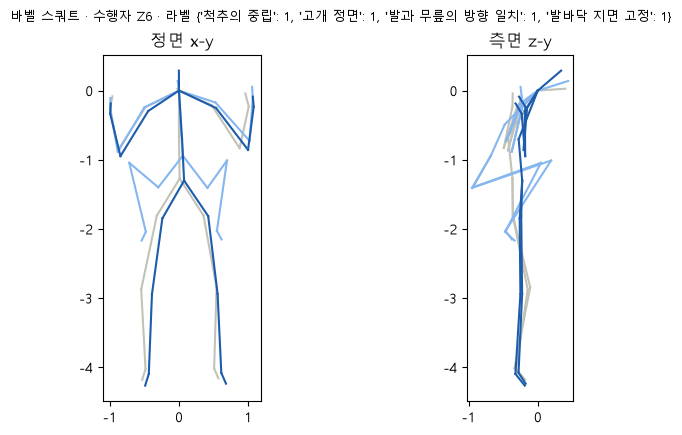

In [5]:
# 한 클립의 정규화 3D 골격 (프레임 1, 9, 16)
BONES = [("Neck","Nose"),("Neck","Left Shoulder"),("Neck","Right Shoulder"),("Left Shoulder","Left Elbow"),("Left Elbow","Left Wrist"),
         ("Left Wrist","Left Palm"),("Right Shoulder","Right Elbow"),("Right Elbow","Right Wrist"),("Right Wrist","Right Palm"),("Neck","Back"),
         ("Back","Waist"),("Waist","Left Hip"),("Waist","Right Hip"),("Left Hip","Left Knee"),("Left Knee","Left Ankle"),("Left Ankle","Left Foot"),
         ("Right Hip","Right Knee"),("Right Knee","Right Ankle"),("Right Ankle","Right Foot")]
i = int(np.where(ex == "바벨 스쿼트")[0][0]); a = norm3d(X3[[i]])[0].reshape(16, 24, 3)
fig, axs = plt.subplots(1, 2, figsize=(8, 4.5))
for ax, (u, v, nm) in zip(axs, [(0, 1, "정면 x-y"), (2, 1, "측면 z-y")]):
    for t, c in zip([0, 8, 15], ["#c3c2b7", "#86b6ef", "#1c5cab"]):
        for b0, b1 in BONES:
            p = a[t, [JOINTS.index(b0), JOINTS.index(b1)]]; ax.plot(p[:, u], p[:, v], color=c, lw=1.5)
    ax.set_aspect("equal"); ax.set_title(nm)
fig.suptitle(f"{metas[i]['exercise']} · 수행자 {metas[i]['z']} · 라벨 {dict(zip(metas[i]['names'], metas[i]['vals']))}", fontsize=9); plt.show()

## 3. 기준 모델 — 요약 특징 + 로지스틱 회귀 (수행자 분리 8-fold)

시퀀스 `(16, F)` → 프레임 축의 **평균 · 표준편차 · 가동범위** `(3F)` → 표준화 + LogReg(C=0.1), 조건마다 이진 분류.
아래는 **랫풀 다운** 한 운동으로 직접 실행한 예입니다 (3D 좌표 vs 3D 좌표 + 관절각).

In [6]:
from sklearn.model_selection import GroupKFold
def run(exercise, S_fn, model="logreg", seed=0):
    ids = np.where(ex == exercise)[0]; S = S_fn(ids); Y = np.array([metas[i]["vals"] for i in ids]); G = np.array([metas[i]["z"] for i in ids])
    P = np.zeros(Y.shape); t0 = time.time()
    for fi, (tr, te) in enumerate(GroupKFold(8).split(S, Y, G)):
        P[te], _ = fit_predict(model, S[tr], Y[tr], G[tr], S[te], seed + fi, 150)
    names = metas[ids[0]]["names"]
    return pd.DataFrame([dict(condition=n, **metrics(Y[:, j], P[:, j])) for j, n in enumerate(names)]).set_index("condition"), time.time() - t0

S3 = lambda ids: norm3d(X3[ids])
S3a = lambda ids: np.concatenate([norm3d(X3[ids]), angles3d(X3[ids].astype(float)).astype(np.float32)], -1)
r1, t1 = run("랫풀 다운", S3); r2, t2 = run("랫풀 다운", S3a)
pd.concat({"3D 좌표": r1[["bal_acc", "auroc"]], "3D 좌표+관절각": r2[["bal_acc", "auroc"]]}, axis=1)

3D 좌표        3D 좌표+관절각       
                   bal_acc  auroc   bal_acc  auroc
condition                                         
수축 시 적당한 상체 젖힘       0.878  0.950     0.876  0.949
손목의 중립               0.773  0.852     0.860  0.940
이완 시 숄더패킹            0.674  0.744     0.663  0.739
수축 시 몸통-팔꿈치 사이 모아줌   0.895  0.959     0.902  0.960

→ **손목의 중립**이 관절각을 넣으면 크게 좋아집니다(표현의 문제), **이완 시 숄더패킹**은 그대로입니다(관측의 문제). 41종 전체 결과는 5절.

## 4. 딥러닝 모델 — 1D-CNN, GRU (운동별 다중 라벨)

- 입력 `(16 프레임, F)`, 출력 = 조건 수만큼 **sigmoid** (binary cross-entropy, Adam 1e-3, batch 32)
- 학습 폴드 안에서 **수행자 15%** 를 검증으로 떼어 조기 종료(patience 15) — 테스트 수행자 누수 없음
- 기준 모델과 **같은 폴드**로 비교

In [7]:
for kind in ["cnn", "gru"]:
    make_keras(kind, 16, 72, 4, 0).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 16, 72)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gaussian_noise      │ (None, 16, 72)    │          0 │ input_layer[0][0] │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 16, 64)    │     13,824 │ gaussian_noise[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 16, 64)    │        256 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 16, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 16, 64)    │     12,288 │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 64)    │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 16, 64)    │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ re_lu_1[0][0]     │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 64)        │          0 │ re_lu_1[0][0]     │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │        516 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 27,140 (106.02 KB)

 Trainable params: 26,884 (105.02 KB)

 Non-trainable params: 256 (1.00 KB)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16, 72)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_1                │ (None, 16, 72)         │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        26,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,756 (104.52 KB)

 Trainable params: 26,756 (104.52 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
res = {"LogReg": r1["bal_acc"]}
for kind in ["cnn", "gru"]:
    r, t = run("랫풀 다운", S3, kind); res[kind.upper()] = r["bal_acc"]; print(f"{kind}: 8-fold {t:.0f}s")
pd.DataFrame(res).assign(**{"(평균)": lambda d: d.mean(1)})

cnn: 8-fold 59s


gru: 8-fold 66s


,LogReg,CNN,GRU,(평균)
condition,,,,
수축 시 적당한 상체 젖힘,0.878,0.879,0.901,0.886
손목의 중립,0.773,0.732,0.725,0.744
이완 시 숄더패킹,0.674,0.699,0.667,0.680
수축 시 몸통-팔꿈치 사이 모아줌,0.895,0.863,0.888,0.882


### 4-1. 학습 곡선 (에폭별 loss)
랫풀 다운, 수행자 분리 폴드 1개에서 1D-CNN·GRU 를 학습하며 에폭마다 train/val loss(binary cross-entropy)를 기록합니다. 점선 = 조기 종료가 고른 최적 에폭(val loss 최소).

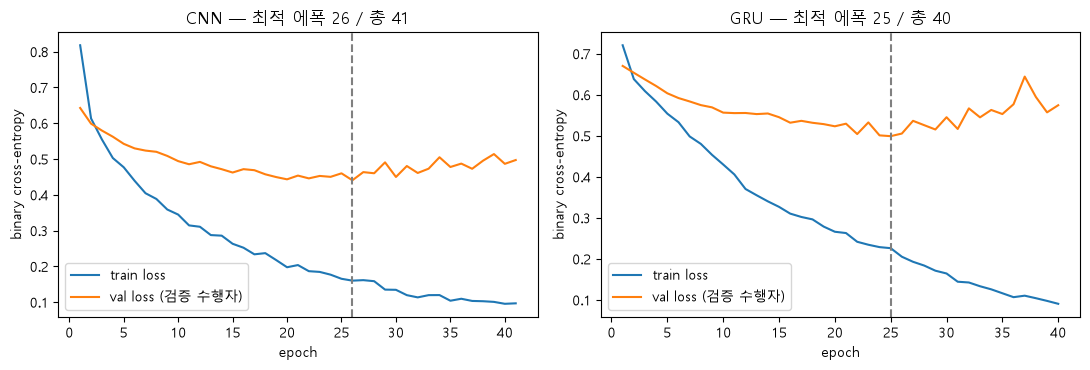

loss  val_loss
    epoch                 
cnn 0      0.818     0.642
    25     0.160     0.441
    40     0.097     0.497
gru 0      0.720     0.670
    24     0.226     0.499
    39     0.090     0.574

In [9]:
import keras
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
ids = np.where(ex == "랫풀 다운")[0]; S = norm3d(X3[ids]); Y = np.array([metas[i]["vals"] for i in ids]); G = np.array([metas[i]["z"] for i in ids])
tr, te = next(GroupKFold(8).split(S, Y, G))
mu, sd = S[tr].mean((0, 1)), S[tr].std((0, 1)) + 1e-6; Str = (S[tr] - mu) / sd
itr, iva = next(GroupShuffleSplit(1, test_size=0.15, random_state=0).split(Str, groups=G[tr]))
hist = {}
for kind in ["cnn", "gru"]:
    m = make_keras(kind, 16, Str.shape[2], Y.shape[1], 0)
    h = m.fit(Str[itr], Y[tr][itr].astype("float32"), validation_data=(Str[iva], Y[tr][iva].astype("float32")), epochs=150, batch_size=32,
              callbacks=[keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)], verbose=0)
    hist[kind] = pd.DataFrame(h.history).rename_axis("epoch")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (k, h) in zip(axs, hist.items()):
    ax.plot(h.index + 1, h["loss"], label="train loss"); ax.plot(h.index + 1, h["val_loss"], label="val loss (검증 수행자)")
    best = int(h["val_loss"].idxmin()) + 1; ax.axvline(best, ls="--", c="gray")
    ax.set_title(f"{k.upper()} — 최적 에폭 {best} / 총 {len(h)}"); ax.set_xlabel("epoch"); ax.set_ylabel("binary cross-entropy"); ax.legend()
plt.tight_layout(); plt.show()
curves = pd.concat(hist, names=["model"]).reset_index(); curves.to_csv("results/tables/training_curves.csv", index=False, encoding="utf-8-sig")
pd.concat({k: h.iloc[[0, int(h["val_loss"].idxmin()), len(h) - 1]] for k, h in hist.items()}).round(4)

### 4-2. 모델 비교 — 단일 시드 vs 3시드 앙상블 (대표 6종, 3D, 조건 26개 평균)

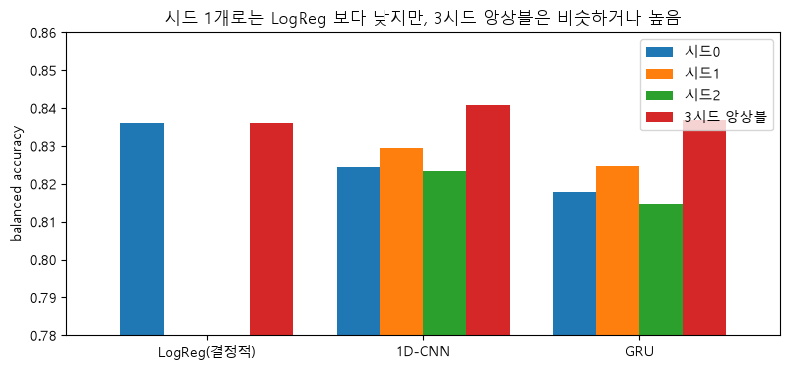

,시드0,시드1,시드2,3시드 앙상블
LogReg(결정적),0.836,NaN,NaN,0.836
1D-CNN,0.825,0.830,0.823,0.841
GRU,0.818,0.825,0.815,0.837


In [10]:
sr = pd.read_csv("results/tables/rep6_3d_seed_robustness.csv"); W6 = pd.read_csv("results/tables/rep6_3d_model_compare.csv")
m = sr.groupby("model")[["seed0", "seed1", "seed2"]].mean()
tab = pd.DataFrame({"시드0": [W6.logreg_bal_acc.mean(), *m.loc[["cnn", "gru"], "seed0"]], "시드1": [np.nan, *m.loc[["cnn", "gru"], "seed1"]],
                    "시드2": [np.nan, *m.loc[["cnn", "gru"], "seed2"]], "3시드 앙상블": [W6.logreg_bal_acc.mean(), W6.cnn_bal_acc.mean(), W6.gru_bal_acc.mean()]},
                   index=["LogReg(결정적)", "1D-CNN", "GRU"])
ax = tab.plot.bar(figsize=(8, 3.8), rot=0, ylim=(0.78, 0.86), width=0.8); ax.set_ylabel("balanced accuracy"); ax.set_title("시드 1개로는 LogReg 보다 낮지만, 3시드 앙상블은 비슷하거나 높음")
plt.tight_layout(); plt.show(); tab.round(3)

한 번의 학습(시드 1개)은 무작위성이 커서, 본 실험에서는 대표 6종에 **시드 3개 × 8폴드**로 학습하고 확률을 평균(앙상블)했습니다:

```
python exp_seq.py --input 3d --exercises rep6 --models logreg,cnn,gru --out results/rep6_3d
python exp_seq.py --input 3d --exercises rep6 --models cnn,gru --seed 100 --out results/rep6_3d_seed1   # seed 200 → seed2
python exp_seq.py --input 2d --exercises rep6 --models logreg,cnn,gru --out results/rep6_2d
python exp_seq.py --input 3d_ang --exercises rep6 --models logreg,cnn,gru --out results/rep6_3d_ang
python exp_seq.py --input {3d,2d,3d_ang,2dv1..2dv5} --exercises all --models logreg --out results/all_logreg_...
python analyze_results.py      # 표 results/tables/, 그림 figures/
```

### 4-3. 분류 보고서와 혼동 행렬 — 덤벨 컬 (수행자 분리 아웃오브폴드 예측, `make_ppt_figs.py`)

f1        precision        recall       
cls                      오류    올바름        오류    올바름     오류    올바름
model  condition                                                 
cnn    손목의 중립         0.518  0.616     0.593  0.560  0.460  0.685
       수축 시 어깨 으쓱 없음  0.887  0.885     0.878  0.895  0.897  0.875
       이완 시 팔 긴장 유지   0.658  0.672     0.672  0.658  0.644  0.686
       척추의 중립         0.881  0.891     0.925  0.854  0.840  0.932
       팔꿈치 위치 고정      0.888  0.896     0.924  0.865  0.856  0.929
logreg 손목의 중립         0.621  0.653     0.651  0.627  0.594  0.682
       수축 시 어깨 으쓱 없음  0.870  0.872     0.877  0.865  0.862  0.879
       이완 시 팔 긴장 유지   0.648  0.651     0.651  0.647  0.644  0.654
       척추의 중립         0.860  0.870     0.896  0.839  0.826  0.904
       팔꿈치 위치 고정      0.879  0.883     0.893  0.870  0.867  0.896

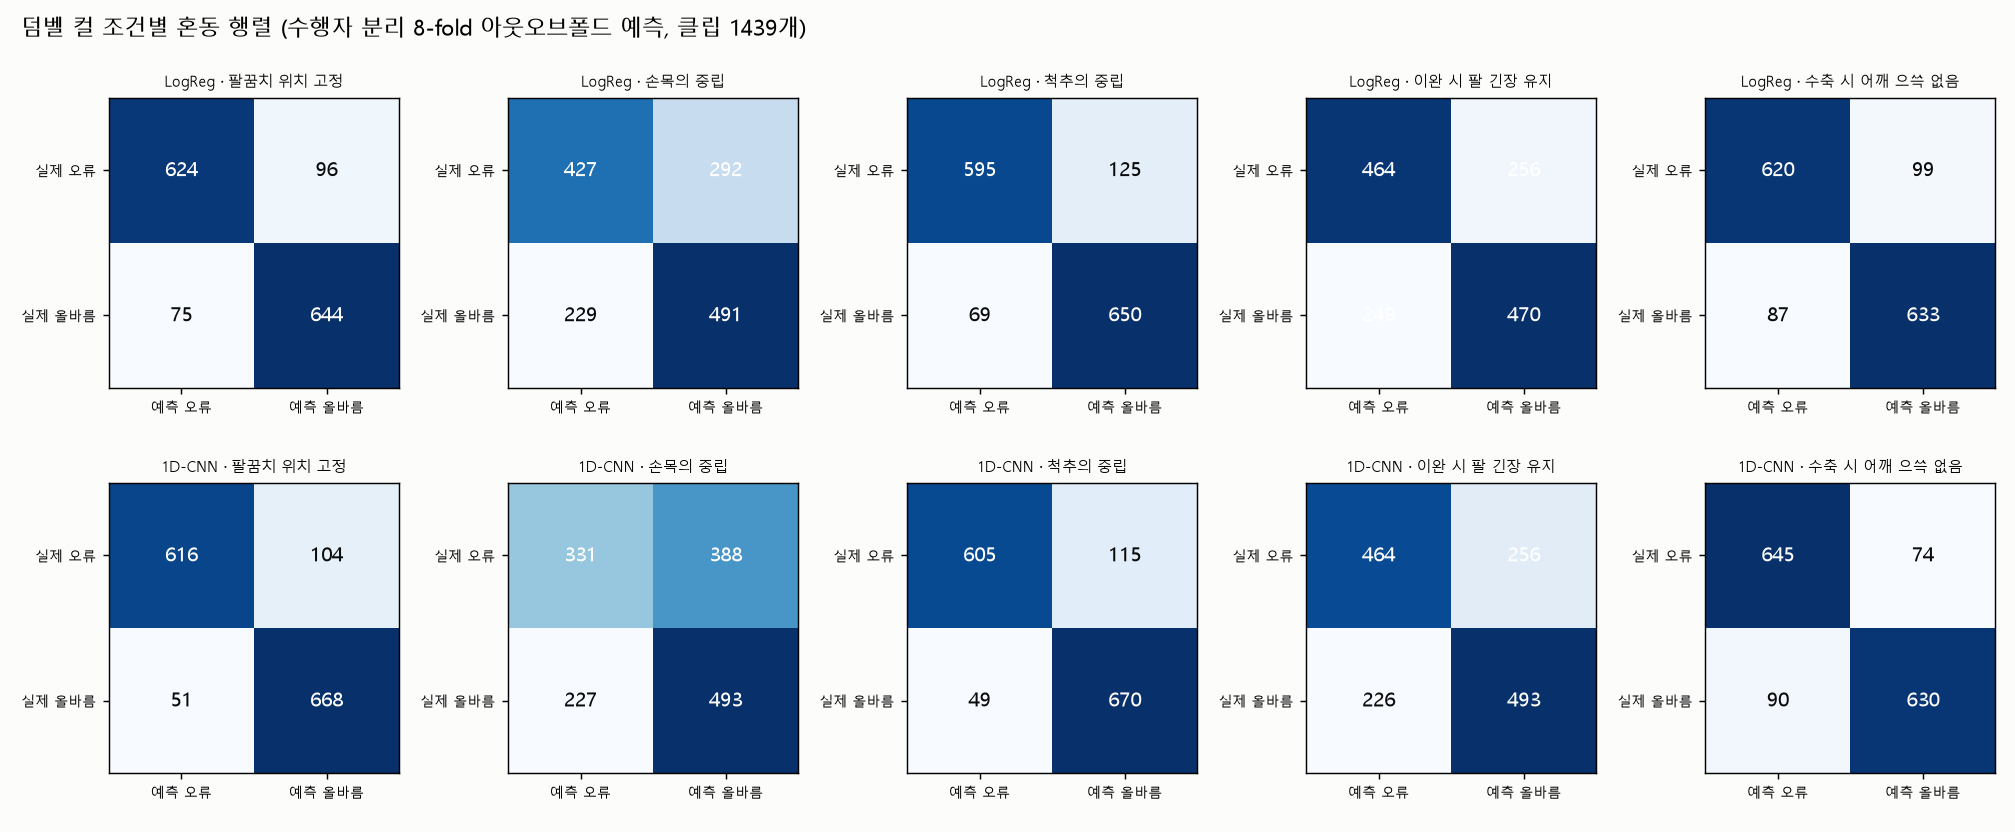

In [11]:
rep = pd.read_csv("results/tables/classification_report_dumbbell_curl.csv")
display(rep[rep.cls != "accuracy"].pivot_table(index=["model", "condition"], columns="cls", values=["precision", "recall", "f1"]).round(3))
display(Image("figures/fig9_confusion_dumbbell_curl.png", width=950))

## 5. 결과
### 탐색적 데이터 분석(EDA)과 구축 프로세스

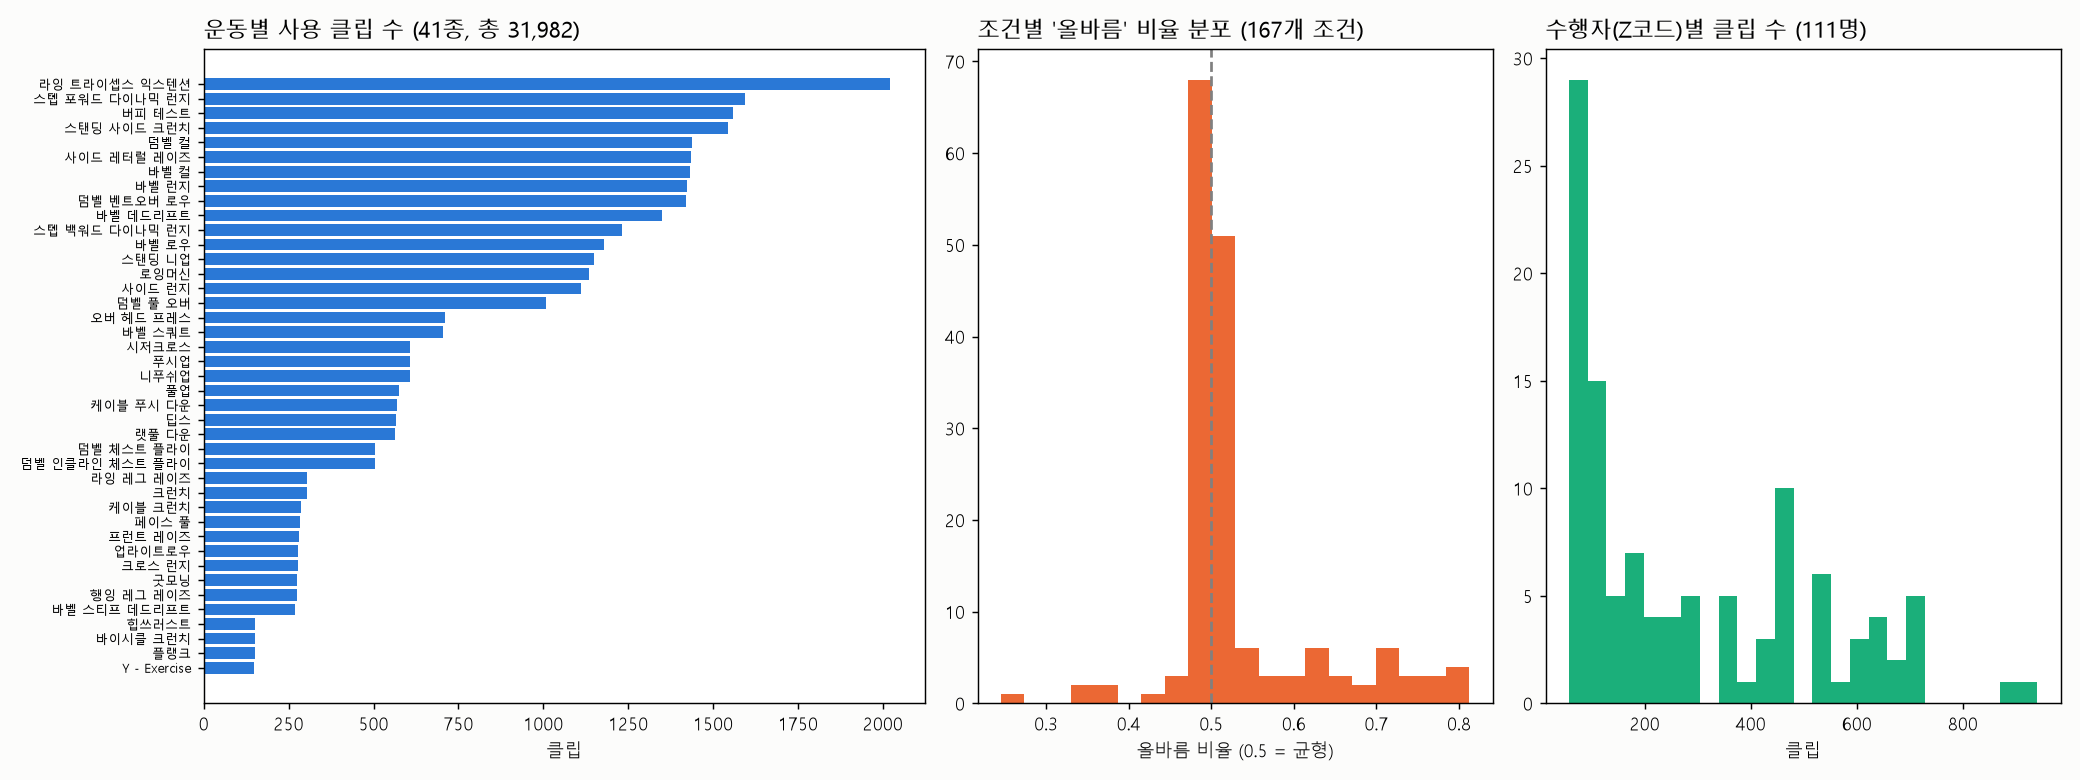

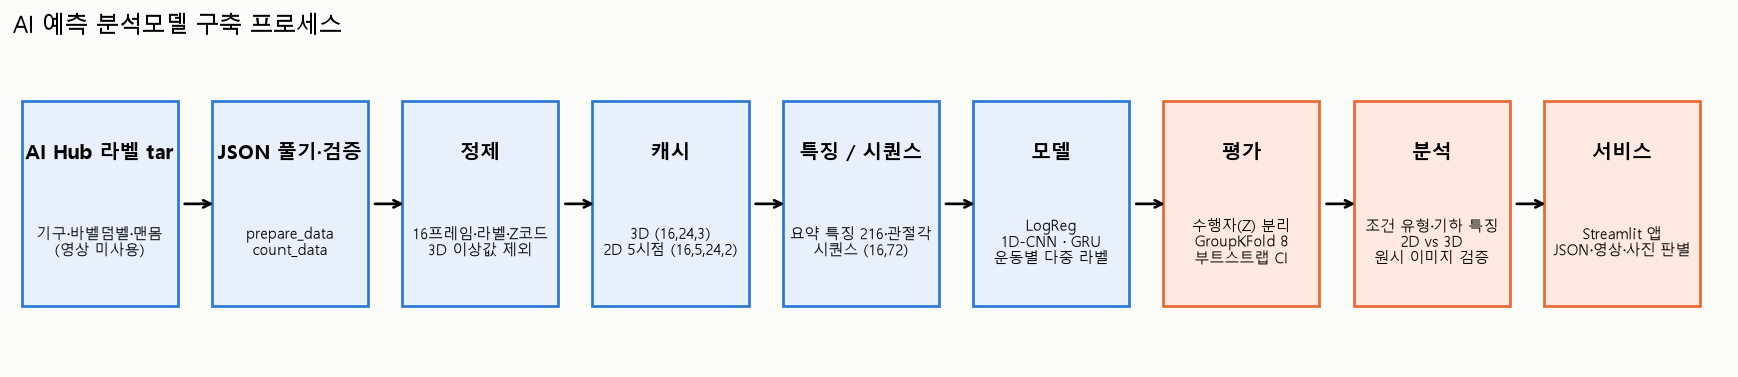

In [12]:
display(Image("figures/fig10_eda.png", width=950)); display(Image("figures/fig11_pipeline.png", width=950))

### RQ1 — 41종 운동별 판별 성능 (3D 요약특징 + LogReg)

조건 167개 | balanced acc 평균 0.792 (중앙값 0.807) | AUROC 평균 0.858 | 0.80 이상 89개


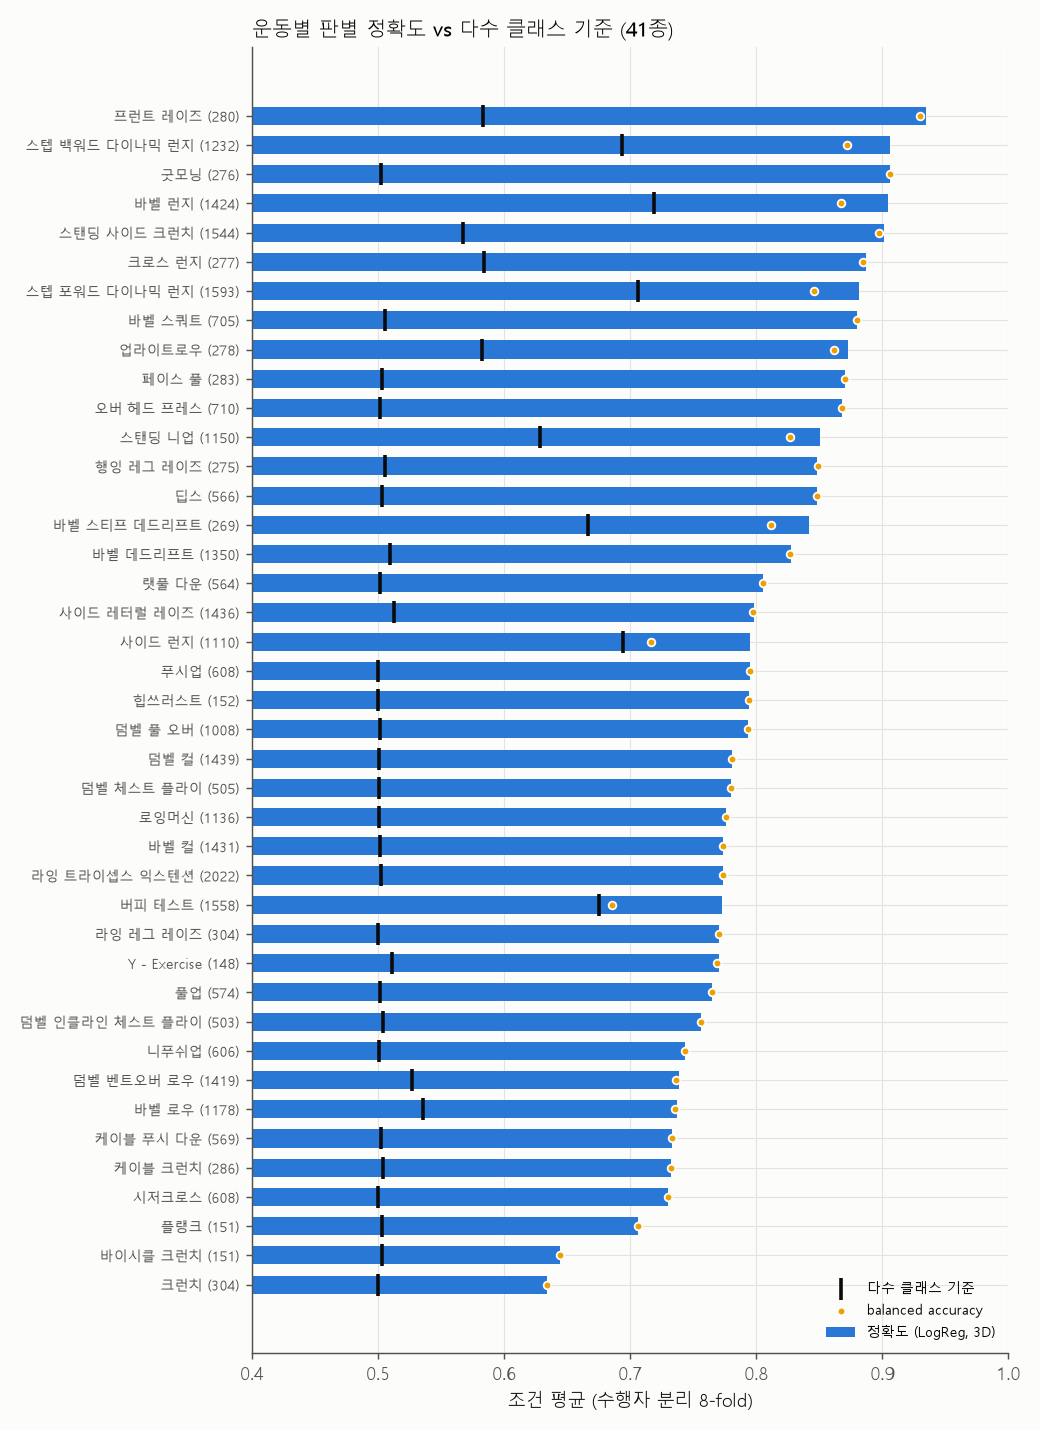

In [13]:
A3 = pd.read_csv("results/all_logreg_3d_paired_metrics.csv")
print(f"조건 {len(A3)}개 | balanced acc 평균 {A3.bal_acc.mean():.3f} (중앙값 {A3.bal_acc.median():.3f}) | AUROC 평균 {A3.auroc.mean():.3f} | 0.80 이상 {(A3.bal_acc >= .8).sum()}개")
display(Image("figures/fig1_exercise_acc_vs_majority.png", width=650))

,type,n,acc,bal_acc,auroc,gain_over_majority
9,시선·고개,13,0.847,0.846,0.908,0.339
8,어깨 으쓱,4,0.832,0.832,0.896,0.331
7,기타(궤적·위치 등),19,0.836,0.824,0.888,0.304
6,무릎·다리·발,33,0.839,0.813,0.884,0.228
5,팔꿈치·팔,26,0.815,0.812,0.879,0.298
4,척추·상체·허리,41,0.801,0.791,0.855,0.242
3,반동·흔들림,9,0.780,0.779,0.851,0.265
2,견갑(숄더패킹·하강·고정),4,0.742,0.742,0.804,0.241
1,손목 중립/각도,9,0.676,0.675,0.735,0.164
0,이완/긴장 유지,9,0.665,0.657,0.711,0.141


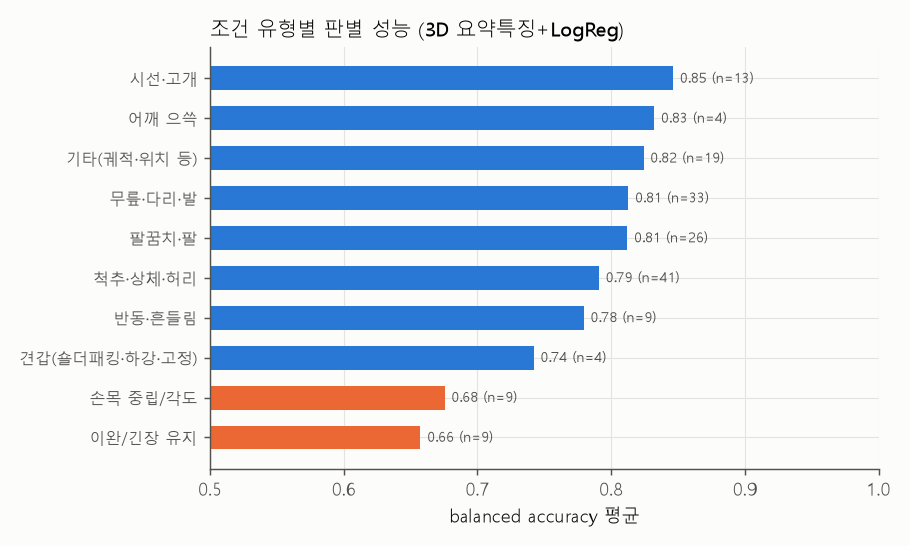

In [14]:
display(pd.read_csv("results/tables/condition_type_summary.csv").sort_values("bal_acc", ascending=False))
display(Image("figures/fig2_condition_type.png", width=650))

### RQ2 — 시퀀스 딥러닝 vs 기준 모델 (대표 6종, CNN·GRU는 3시드 앙상블)

,seed0,seed1,seed2,앙상블
model,,,,
cnn,0.825,0.830,0.823,0.841
gru,0.818,0.825,0.815,0.837
logreg,0.836,0.836,0.836,0.836


,exercise,condition,logreg_bal_acc,cnn_bal_acc,gru_bal_acc,cnn-logreg_CI,gru-logreg_CI,hard
0,랫풀 다운,수축 시 적당한 상체 젖힘,0.878,0.901,0.887,"[-0.007, +0.053]","[-0.014, +0.031]",False
1,랫풀 다운,손목의 중립,0.773,0.759,0.757,"[-0.041, +0.009]","[-0.054, +0.026]",True
2,랫풀 다운,이완 시 숄더패킹,0.674,0.697,0.688,"[-0.008, +0.051]","[-0.016, +0.046]",True
3,랫풀 다운,수축 시 몸통-팔꿈치 사이 모아줌,0.895,0.885,0.906,"[-0.039, +0.016]","[-0.009, +0.033]",False
4,딥스,상체 살짝 숙임 유지,0.807,0.790,0.793,"[-0.051, +0.018]","[-0.041, +0.014]",False
5,딥스,수축 시 고개 안 젖힘,0.809,0.815,0.841,"[-0.023, +0.036]","[-0.002, +0.062]",False
6,딥스,이완 시 팔꿈치 각도 90도,0.899,0.812,0.837,"[-0.131, -0.042]","[-0.092, -0.029]",False
7,딥스,팔꿈치-몸통의 적당한 거리,0.876,0.830,0.832,"[-0.079, -0.013]","[-0.077, -0.013]",False
8,바벨 스쿼트,척추의 중립,0.885,0.886,0.898,"[-0.021, +0.023]","[-0.004, +0.030]",False
9,바벨 스쿼트,고개 정면,0.867,0.901,0.895,"[+0.008, +0.063]","[+0.002, +0.055]",False


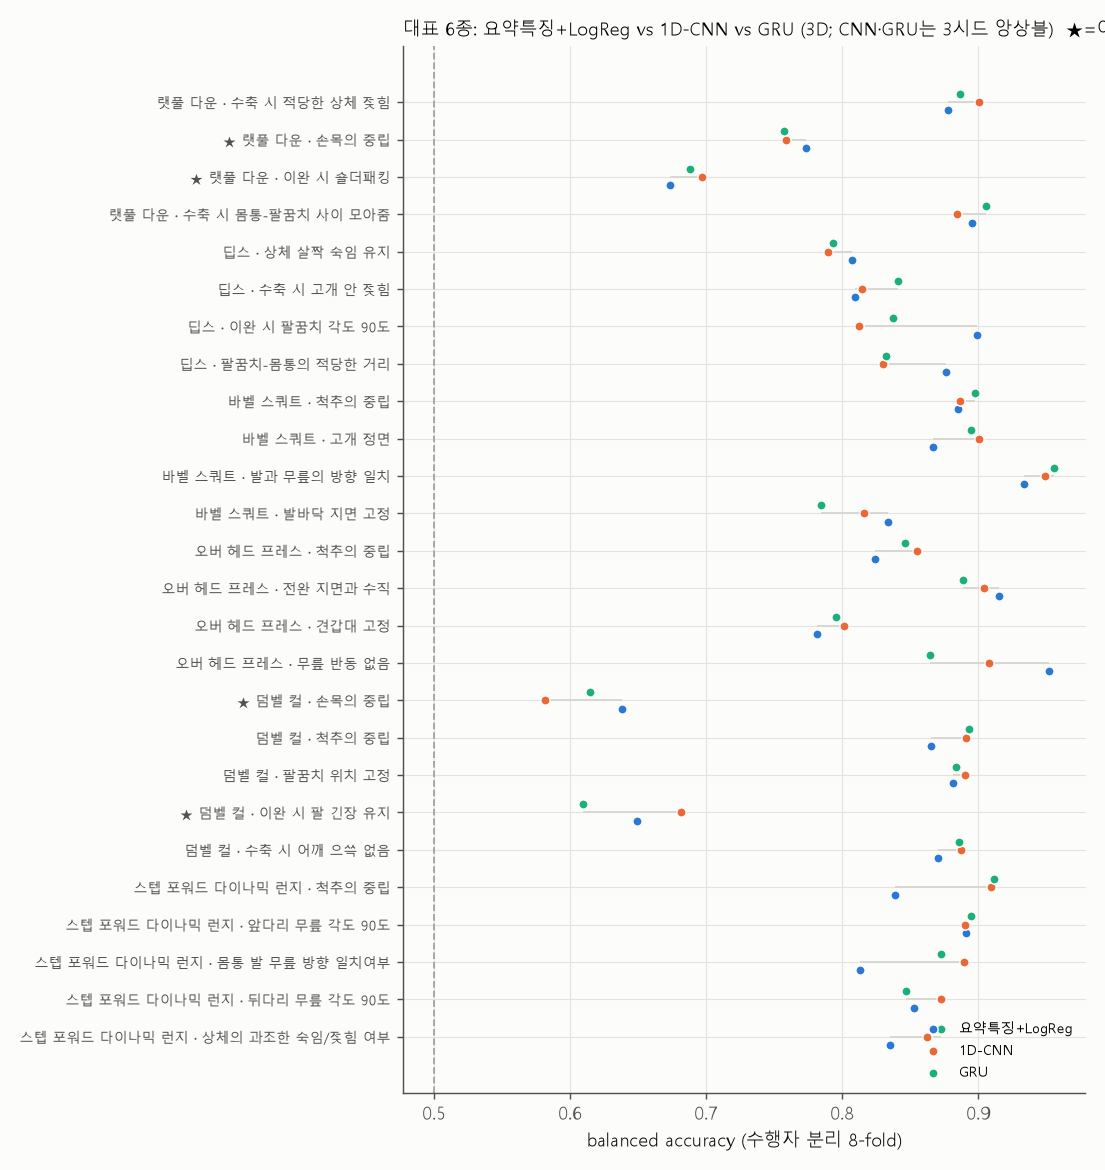

In [15]:
sr = pd.read_csv("results/tables/rep6_3d_seed_robustness.csv")
W = pd.read_csv("results/tables/rep6_3d_model_compare.csv")
display(sr.groupby("model")[["seed0", "seed1", "seed2"]].mean().assign(앙상블=[W.cnn_bal_acc.mean(), W.gru_bal_acc.mean()]).T.assign(logreg=W.logreg_bal_acc.mean()).T)
display(W[["exercise", "condition", "logreg_bal_acc", "cnn_bal_acc", "gru_bal_acc", "cnn-logreg_CI", "gru-logreg_CI", "hard"]])
display(Image("figures/fig3_rep6_models_3d.png", width=700))

In [16]:
display(Markdown("**어려운 조건 vs 나머지** (3시드 앙상블)")); display(pd.read_csv("results/tables/rep6_3d_hard_vs_rest.csv"))
display(Markdown("**입력 표현 변경: 3D vs 3D+관절각** (시드 0)")); display(pd.read_csv("results/tables/rep6_3d_vs_3d_ang_mean.csv"))

**어려운 조건 vs 나머지** (3시드 앙상블)

,Unnamed: 0,logreg_bal_acc,cnn_bal_acc,gru_bal_acc,n
0,어려운 조건(손목·긴장 유지·숄더패킹),0.683,0.68,0.667,4
1,나머지 조건,0.864,0.87,0.868,22


**입력 표현 변경: 3D vs 3D+관절각** (시드 0)

,hard,logreg_3d,cnn_3d,gru_3d,logreg_3d_ang,cnn_3d_ang,gru_3d_ang
0,나머지 조건,0.864,0.853,0.848,0.869,0.862,0.858
1,어려운 조건,0.683,0.667,0.649,0.723,0.731,0.705
2,전체,0.836,0.825,0.818,0.846,0.842,0.835


### RQ3 — 3D vs 2D 5시점 vs 카메라 1대 (41종 LogReg, 같은 클립·같은 폴드)

,클립 집합,clips,bal_acc 평균(조건),AUROC 평균(조건)
0,3D (paired),31982,0.792,0.858
1,"2D 5시점 (paired, 같은 클립)",31982,0.802,0.864
2,"2D 5시점 (all2d, 2D 전용 포함)",34181,0.801,0.865


,type,n,3D,2D 5시점,2D 시점A,2D 시점B,2D 시점C,2D 시점D,2D 시점E,단일 시점 평균
0,견갑(숄더패킹·하강·고정),4,0.742,0.728,0.707,0.713,0.717,0.711,0.707,0.711
1,기타(궤적·위치 등),19,0.824,0.833,0.816,0.826,0.772,0.787,0.790,0.798
2,무릎·다리·발,33,0.813,0.828,0.780,0.795,0.757,0.796,0.786,0.783
3,반동·흔들림,9,0.779,0.795,0.774,0.774,0.747,0.775,0.782,0.771
4,손목 중립/각도,9,0.675,0.696,0.654,0.680,0.640,0.673,0.663,0.662
5,시선·고개,13,0.846,0.843,0.819,0.833,0.840,0.801,0.795,0.818
6,어깨 으쓱,4,0.832,0.850,0.811,0.834,0.810,0.842,0.810,0.821
7,이완/긴장 유지,9,0.657,0.643,0.621,0.641,0.619,0.634,0.628,0.628
8,척추·상체·허리,41,0.791,0.803,0.774,0.784,0.761,0.776,0.767,0.772
9,팔꿈치·팔,26,0.812,0.823,0.796,0.800,0.775,0.786,0.778,0.787


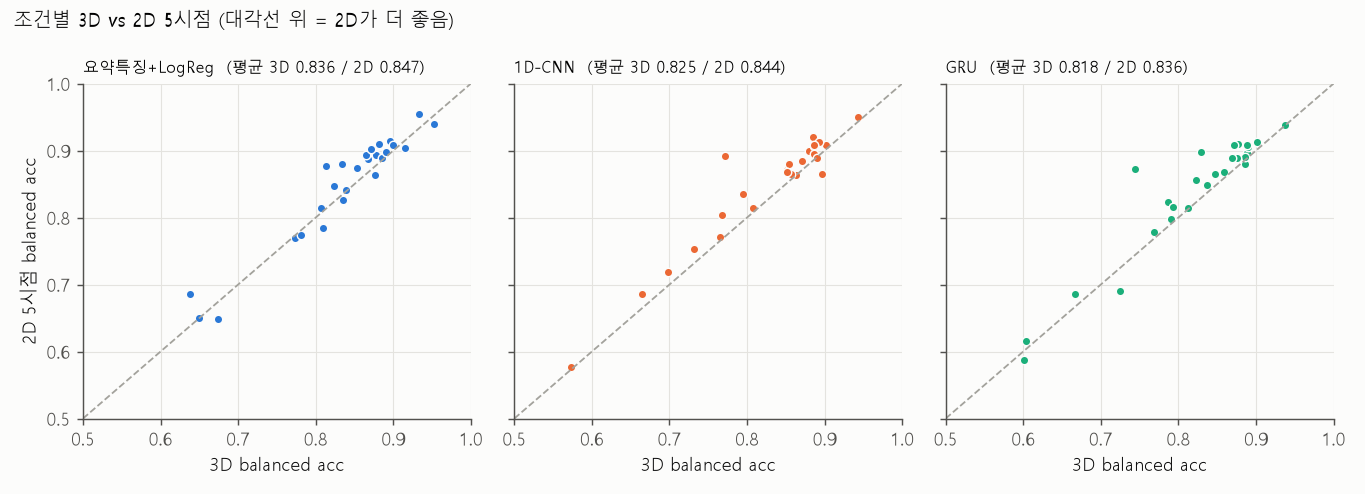

In [17]:
display(pd.read_csv("results/tables/all41_2d_vs_3d_overall.csv"))
display(pd.read_csv("results/tables/all41_single_view_by_type.csv"))
display(Image("figures/fig4_2d_vs_3d_rep6.png", width=800))

### RQ4 — 어려운 조건은 왜 어려운가
조건 정의에 대응하는 **기하 특징 1개**(학습 없음)의 AUROC vs 216특징 LogReg AUROC

,feature,exercise,condition,clips,single_feature_auroc,mean_true,mean_false,logreg_auroc
0,손목 꺾임 각(평균),덤벨 벤트오버 로우,손목의 중립,1419,0.886,9.551,19.506,0.694
1,손목 꺾임 각(평균),덤벨 컬,손목의 중립,1439,0.778,10.883,17.389,0.687
2,손목 꺾임 각(평균),덤벨 풀 오버,손목의 중립,1008,0.705,28.551,22.714,0.760
3,손목 꺾임 각(평균),라잉 트라이셉스 익스텐션,손목의 중립,2022,0.816,25.014,37.964,0.785
4,손목 꺾임 각(평균),랫풀 다운,손목의 중립,564,0.867,13.608,22.956,0.852
5,손목 꺾임 각(평균),바벨 로우,손목의 중립,1178,0.796,11.317,19.308,0.695
6,손목 꺾임 각(평균),바벨 컬,손목의 중립,1431,0.745,10.875,15.896,0.675
7,손목 꺾임 각(평균),사이드 레터럴 레이즈,손목의 각도 고정,1436,0.728,10.725,15.331,0.712
8,손목 꺾임 각(평균),케이블 푸시 다운,손목의 중립,569,0.819,16.665,26.536,0.753
9,팔꿈치 최대 각,덤벨 컬,이완 시 팔 긴장 유지,1439,0.584,170.529,171.934,0.705


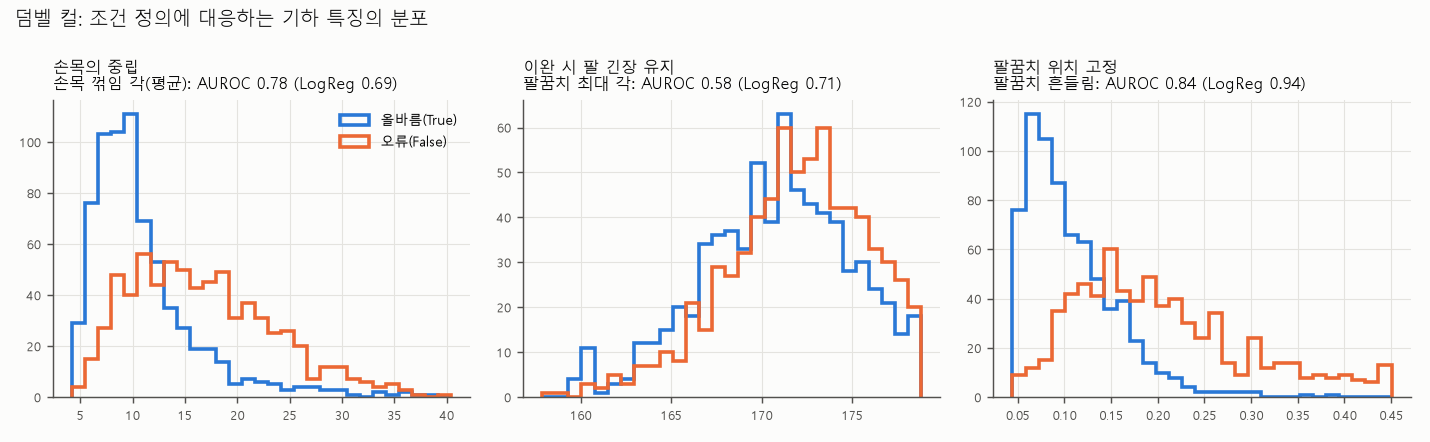

In [18]:
display(pd.read_csv("results/tables/geometric_feature_auroc.csv"))
display(Image("figures/fig7_geometric_features_dumbbell_curl.png", width=850))

,type,n,bal_acc_3d,bal_acc_3d_ang,auroc_3d,auroc_3d_ang,improved
0,이완/긴장 유지,9,0.657,0.652,0.711,0.705,3
1,손목 중립/각도,9,0.675,0.761,0.735,0.832,9
2,견갑(숄더패킹·하강·고정),4,0.742,0.748,0.804,0.812,2
3,반동·흔들림,9,0.779,0.814,0.851,0.874,8
4,척추·상체·허리,41,0.791,0.792,0.855,0.857,23
5,팔꿈치·팔,26,0.812,0.811,0.879,0.878,13
6,무릎·다리·발,33,0.813,0.818,0.884,0.887,18
7,기타(궤적·위치 등),19,0.824,0.826,0.888,0.888,11
8,어깨 으쓱,4,0.832,0.859,0.896,0.920,4
9,시선·고개,13,0.846,0.845,0.908,0.906,7


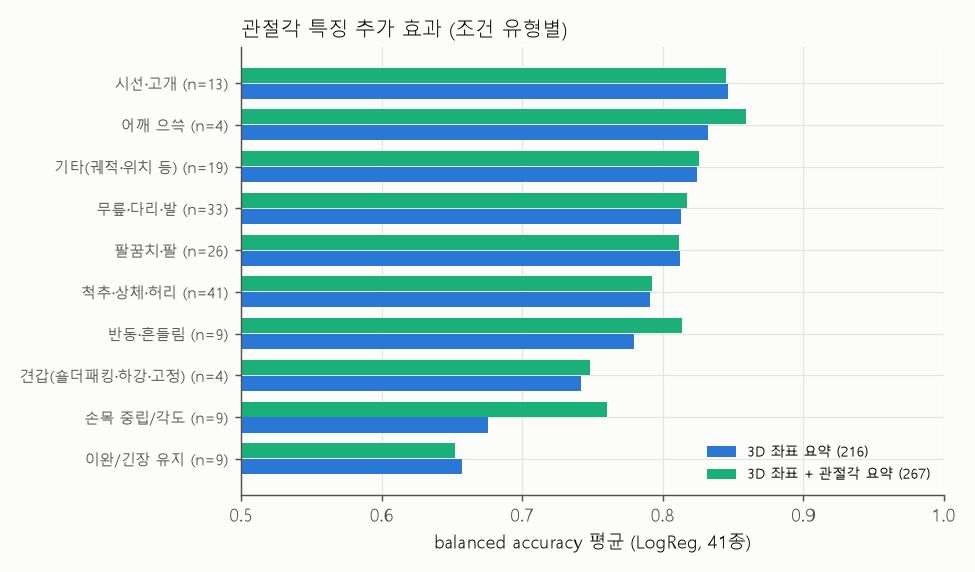

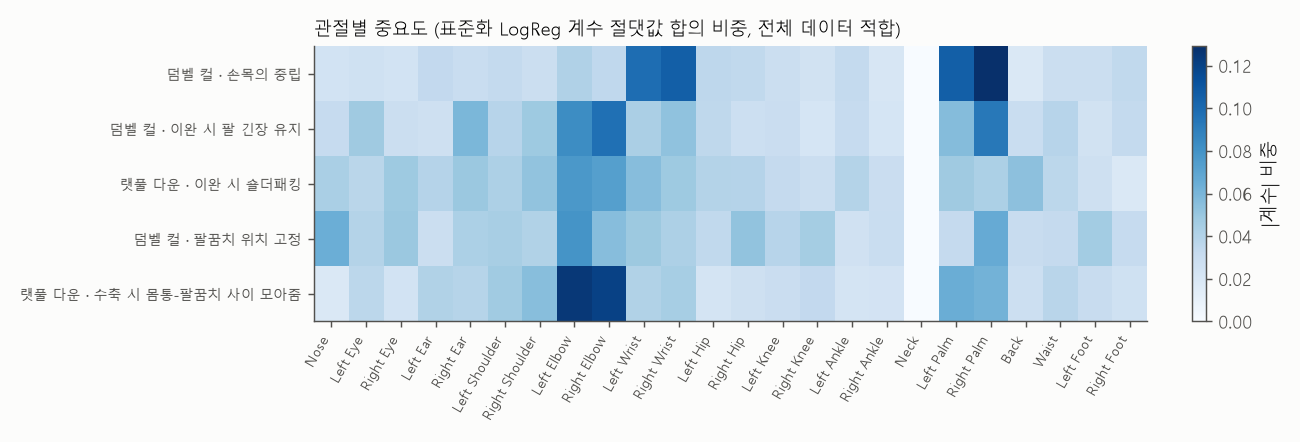

In [19]:
display(pd.read_csv("results/tables/all41_3d_vs_3d_ang_by_type.csv"))
display(Image("figures/fig8_angle_features_by_type.png", width=650))
display(Image("figures/fig5_joint_importance.png", width=850))

## 6. 결론

1. 3D 좌표만으로 167개 조건 평균 balanced accuracy **0.792**, 89개 조건이 0.80 이상 — 시선·고개, 어깨 으쓱, 팔꿈치, 무릎 정렬은 자동 피드백 후보.
2. 1D-CNN·GRU(3시드 앙상블)는 LogReg와 평균이 비슷(0.841/0.837 vs 0.836). 큰 운동에서 낫고 작은 운동에서 못하며, **어려운 조건은 개선하지 못함**. 단일 시드로는 결론이 뒤집힐 수 있음.
3. **손목 중립 = 표현의 문제**: 관절각 특징으로 0.675 → 0.761.
4. **긴장 유지·숄더패킹 = 관측의 문제**: 관절각 차이 2° 미만, 어떤 모델·입력으로도 뚜렷한 개선 없음 → 키포인트 기반 피드백 대상에서 빼거나 다른 센서 필요.
5. 같은 클립에서 2D 5시점(0.802) ≥ 3D(0.792) > 카메라 1대(0.755~0.783).

**한계**: 연기된 오류(실제보다 쉬움), 24관절(손가락·견갑골 없음), 16프레임 고정, 시퀀스 모델은 6종·작은 구조만, Z코드=동일인 가정. 자세한 내용은 `REPORT.md`.

## 7. 시연 앱용 모델 내보내기

Streamlit 앱(`app.py`)은 원본 데이터 없이 동작하도록 **파생물만** 사용합니다 — `python export_models.py`
- `app_data/models.json`: 41종 × 조건별 LogReg 계수(3D 좌표 + 관절각 267특징, 전체 클립 학습) + 교차검증 성능
- `app_data/mean_skeletons.npz`: 조건별 올바름/오류 **평균** 골격(집계값)

In [20]:
mj = json.load(open("app_data/models.json", encoding="utf-8"))["models"]
print("운동", len(mj), "| 조건", sum(len(m["conditions"]) for m in mj.values()), "| 파일 크기", {f: f"{os.path.getsize('app_data/' + f) / 1e6:.2f} MB" for f in os.listdir("app_data")})

운동

 41 | 조건 167 | 파일 크기 {'counts.json': '0.00 MB', 'mean_skeletons.npz': '0.89 MB', 'models.json': '2.82 MB', 'photo_models.json': '0.48 MB'}
